In [39]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

In [40]:
DATA_DIR <- "/home/mariya/Data/pallas/mlomix_datasets"

TRAIN_DATA_DIR <- file.path(DATA_DIR, "labeled-diagnostic-bimodal-reduced")
METH_FILE <- file.path(TRAIN_DATA_DIR, "features.dnam.csv")
GEX_FILE <- file.path(TRAIN_DATA_DIR, "features.gex.csv")
LABELS_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")

MIXOMICS_DIR <- file.path("/home/mariya/Data/pallas/mixOmics")
OUTPUT_DIR <- file.path("/home/mariya/Data/pallas/mixOmics/models_20260807")

# Create output directory if it doesn't exist
if (!dir.exists(OUTPUT_DIR)) {
    dir.create(OUTPUT_DIR, recursive = TRUE)
}

In [41]:
source("helpers.R")
train_data <- data(GEX_FILE, METH_FILE, LABELS_FILE)

Samples: 1227 
GEX features: 1121 
DNAm features: 1186 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [42]:
X.gex <- train_data$X_gex
X.dnam <- train_data$X_dnam
Y     <- train_data$Y

head(X.gex)
head(X.dnam)
head(Y)

,ENSG00000184507,ENSG00000079102,ENSG00000248329,ENSG00000101115,ENSG00000172752,ENSG00000097007,ENSG00000132185,ENSG00000167880,ENSG00000177469,ENSG00000188064,⋯,ENSG00000170396,ENSG00000130702,ENSG00000187325,ENSG00000169213,ENSG00000186980,ENSG00000182747,ENSG00000144681,ENSG00000072954,ENSG00000181007,ENSG00000107819
ALL_1000,-1.608643,-1.608643,15.995107,4.8418488,-1.4407131,6.202016,-0.8269021,0.3324897,1.0468822,-1.306680,⋯,-0.2482395,1.155457,6.090830,-1.60864328,-1.608643,-1.6086433,-1.269090,0.7956456,2.456942,6.361923
ALL_1003,7.866846,-1.608643,-1.608643,-0.1704226,-1.6086433,6.221609,-1.6086433,-0.5538530,-0.7979199,-1.373961,⋯,-1.6086433,-1.147371,4.677110,0.26710648,-1.608643,-1.1408426,-1.608643,-1.2343983,3.309382,5.515478
ALL_1005,-1.608643,-1.608643,-1.608643,3.0300396,-1.5171299,5.962302,5.6071701,0.6443205,-0.6988636,-1.608643,⋯,-1.6086433,1.857859,6.355210,-0.24149963,-1.608643,-1.6086433,3.743243,3.2675844,3.515856,4.569093
ALL_1019,-1.608643,-1.608643,-1.608643,7.0165835,-1.6086433,5.654076,1.5010946,3.2958788,-0.2369391,-1.608643,⋯,-1.6086433,1.988980,5.567993,0.44466570,-1.608643,-1.6086433,-1.161472,3.8516648,2.002225,5.698553
ALL_1023,6.295659,-1.608643,-1.608643,4.0362302,-0.4718155,6.586559,-1.0246909,5.4514953,2.5433950,-1.608643,⋯,0.2861806,-0.133622,4.903089,1.57325962,-1.608643,-0.8427656,-1.364855,0.2819973,2.888247,4.372993
ALL_1026,-1.384271,-1.608643,7.200832,-0.3788483,-1.6086433,6.458333,0.3933072,7.1349388,-0.9366025,7.595660,⋯,-1.6086433,2.223308,5.783929,0.09725186,-1.608643,-1.6086433,-1.608643,1.1623027,2.910556,5.311609


,cg10443049,cg07275648,cg00760938,cg04646674,cg12183594,cg03732020,cg14992144,cg13799263,cg08166720,cg00015639,⋯,cg01955153,cg26092233,cg18631798,cg21927946,cg11551919,cg01883662,cg20294319,cg12737392,cg09291834,cg11414821
ALL_1000,0.8325,0.9452,0.0400,0.9366,0.9854,0.7879,0.0186,0.9181,0.9419,0.2988,⋯,0.1614,0.0677,0.0333,0.2134,0.9773,0.9641,0.0702,0.0862,0.8104,0.0315
ALL_1003,0.9219,0.6754,0.1550,0.9236,0.9849,0.9087,0.0272,0.7213,0.9059,0.7597,⋯,0.0889,0.1056,0.0643,0.7567,0.9731,0.9196,0.0946,0.0913,0.0193,0.0256
ALL_1005,0.9113,0.9435,0.0375,0.6264,0.9850,0.9844,0.0230,0.7807,0.9334,0.9095,⋯,0.2638,0.0489,0.0296,0.0678,0.9645,0.9251,0.0899,0.1216,0.4870,0.0326
ALL_1019,0.7243,0.9433,0.0757,0.9088,0.9829,0.9830,0.0267,0.8941,0.4691,0.6096,⋯,0.1940,0.0529,0.0354,0.0220,0.3327,0.1337,0.0656,0.0774,0.1054,0.0233
ALL_1023,0.8656,0.9308,0.1669,0.8532,0.9857,0.8091,0.0480,0.9283,0.9532,0.8493,⋯,0.2563,0.1559,0.0972,0.0441,0.9504,0.9194,0.0604,0.1027,0.1858,0.0363
ALL_1026,0.9320,0.6853,0.0826,0.8681,0.9848,0.9876,0.0354,0.9055,0.9592,0.7046,⋯,0.1624,0.1184,0.0643,0.0251,0.3294,0.1498,0.0533,0.0888,0.0324,0.0294


[1] B-ALL, DUX4-r      B-ALL, PAX5alt     B-ALL, MEF2D-r     B-ALL, ZNF384-r   
[5] B-ALL, ETV6::RUNX1 B-ALL, PAX5alt    
25 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

In [43]:
# Get num classes from Y
num_classes <- length(unique(Y))
num_classes

[1] 25

In [44]:
NCOMP <- num_classes - 1
KEEP_X <- 30

keepX.gex <- rep(KEEP_X, NCOMP)
keepX.dnam <- rep(KEEP_X, NCOMP)

NCOMP
keepX.gex
keepX.dnam

[1] 24

[1] 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30

[1] 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30

In [45]:
# Single block models
model.gex   <- splsda(X.gex, Y, ncomp = NCOMP, keepX = keepX.gex)
model.dnam  <- splsda(X.dnam, Y, ncomp = NCOMP, keepX = keepX.dnam)

In [46]:
# build blocks as lists (so names(X) works)
X <- list(gex = X.gex, dnam = X.dnam)
keepX <- list(gex = keepX.gex, dnam = keepX.dnam)

# Integrated model (design favors discrimination)
design.int <- matrix(0.1, ncol = 2, nrow = 2, dimnames = list(names(X), names(X)))
diag(design.int) <- 0
model.integrated <- block.splsda(X, Y, ncomp = NCOMP, keepX = keepX, design = design.int)

model.integrated

Design matrix has changed to include Y; each block will be
            linked to Y.




Call:
 block.splsda(X = X, Y = Y, ncomp = NCOMP, keepX = keepX, design = design.int) 

 sGCCA with 24 components on block 1 named gex 
 sGCCA with 24 components on block 2 named dnam 
 sGCCA with 24 components on the outcome Y

 Dimension of block 1 is  1227 1121 
 Dimension of block 2 is  1227 1186 
 Outcome Y has 25 levels 

 Selection of 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 variables on each of the sGCCA components on the block 1 
 Selection of 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 30 variables on each of the sGCCA components on the block 2 

 Main numerical outputs: 
 -------------------- 
 loading vectors: see object$loadings 
 variates: see object$variates 
 variable names: see object$names 

 Functions to visualise samples: 
 -------------------- 
 plotIndiv, plotArrow, cimDiablo, plotDiablo 

 Functions to visualise variables: 
 -------------------- 
 plotVar, plotLoadings, network, circosPlot 

 Other functions

In [47]:
N_FOLDS <- 5
N_REPEATS <- 50
DIST <- "centroids.dist"

# Compare via CV
perf.gex    <- perf(
    model.gex,
    validation = "Mfold",
    folds = N_FOLDS,
    nrepeat = N_REPEATS,
    light.output = FALSE,
    dist = DIST)

perf.gex


Call:
 perf.mixo_splsda(object = model.gex, dist = DIST, validation = "Mfold", folds = N_FOLDS, nrepeat = N_REPEATS, light.output = FALSE) 

 Main numerical outputs: 
 -------------------- 
 Error rate (overall or BER) for each component and for each distance (averaged over the nrepeat): see object$error.rate 
 Error rate (overall or BER) for each component, for each distance and for each repeat: see object$error.rate.all 
 Error rate per class, for each component and for each distance: see object$error.rate.class 
 Prediction values for each component: see object$predict 
 Classification of each sample, for each component and for each distance: see object$class 
 Stable features on each component: see object$features$stable 
 AUC values: see object$auc if auc = TRUE 

 Visualisation Functions: 
 -------------------- 
 plot 

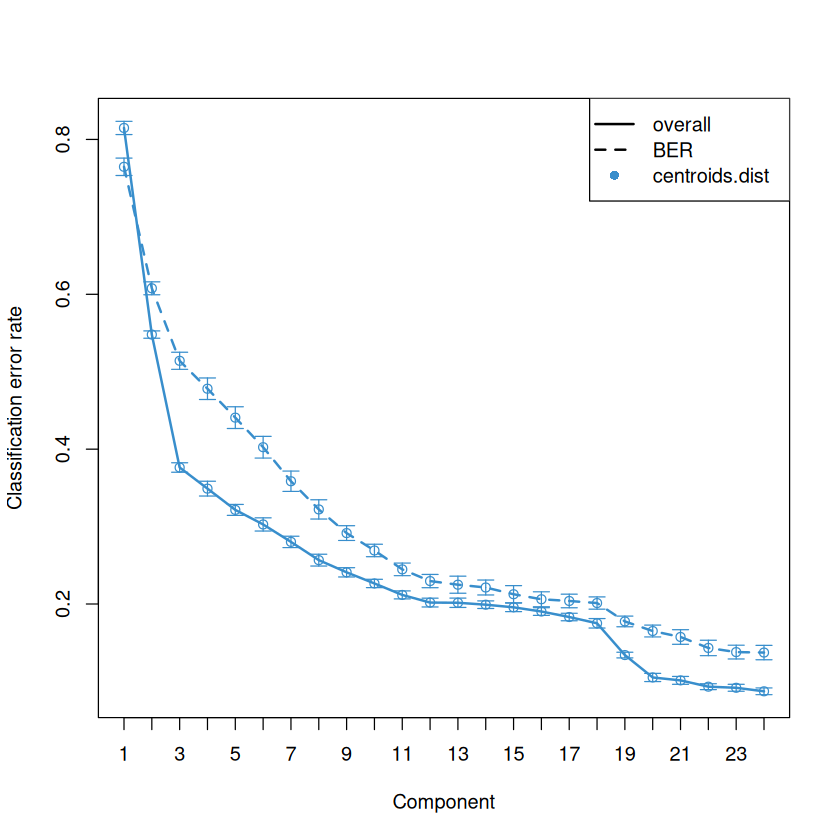

In [48]:
plot(perf.gex, criterion = "BER")

In [49]:
saveRDS(perf.gex, file.path(OUTPUT_DIR, "perf.gex.rds"))

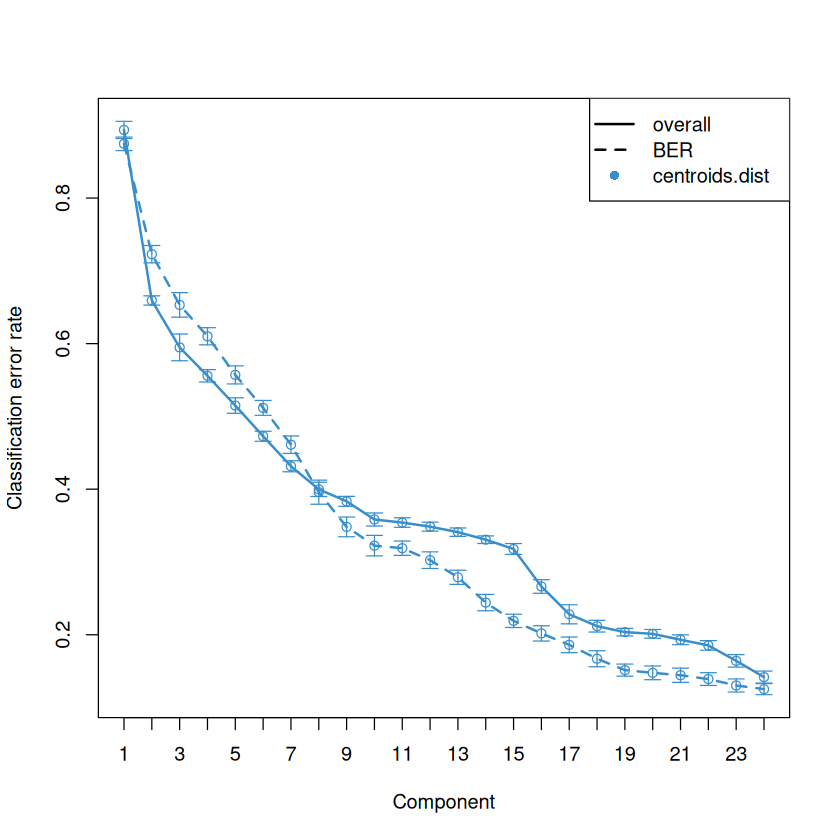

In [50]:

perf.dnam   <- perf(
    model.dnam,
    validation = "Mfold",
    folds = N_FOLDS,
    nrepeat = N_REPEATS,
    light.output = FALSE,
    dist = DIST)
plot(perf.dnam, criterion = "BER")
saveRDS(perf.dnam, file.path(OUTPUT_DIR, "perf.dnam.rds"))


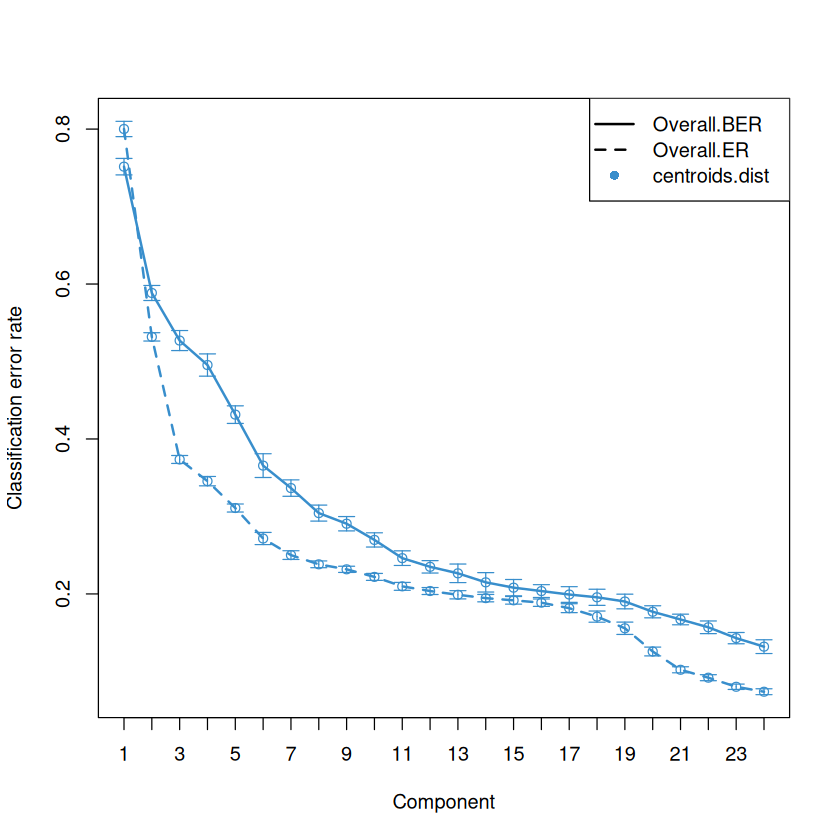

In [51]:
perf.int    <- perf(
    model.integrated,
    validation = "Mfold",
    folds = N_FOLDS,
    nrepeat = N_REPEATS,
    light.output = FALSE,
    dist = DIST)
plot(perf.int, criterion = "BER")
saveRDS(perf.int, file.path(OUTPUT_DIR, "perf.integrated.rds"))

In [52]:
# ============================================================
# Extract optimal ncomp for each
# ============================================================
ncomp_gex    <- perf.gex$choice.ncomp["BER", DIST]
ncomp_dnam   <- perf.dnam$choice.ncomp["BER", DIST]
ncomp_diablo <- perf.int$choice.ncomp$WeightedVote["Overall.BER", DIST]

cat("Optimal ncomp — GEX:", ncomp_gex,
    " DNAm:", ncomp_dnam,
    " DIABLO:", ncomp_diablo, "\n")

Optimal ncomp — GEX: 23  DNAm: 24  DIABLO: 24 


In [53]:
# GEX
cat("=== GEX BER per component ===\n")
print(round(perf.gex$error.rate$BER[, DIST], 3))

# DNAm
cat("\n=== DNAm BER per component ===\n")
print(round(perf.dnam$error.rate$BER[, DIST], 3))

# DIABLO
cat("\n=== DIABLO BER per component ===\n")
diablo_ber <- colMeans(perf.int$WeightedVote.error.rate[[DIST]])
print(round(diablo_ber, 3))

=== GEX BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.765  0.608  0.514  0.478  0.441  0.402  0.359  0.322  0.292  0.269  0.245 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.230  0.225  0.221  0.213  0.206  0.204  0.201  0.177  0.165  0.157  0.143 
comp23 comp24 
 0.138  0.137 

=== DNAm BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.875  0.723  0.653  0.610  0.557  0.512  0.461  0.396  0.348  0.322  0.319 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.302  0.279  0.244  0.219  0.202  0.186  0.167  0.151  0.148  0.144  0.139 
comp23 comp24 
 0.130  0.125 

=== DIABLO BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.753  0.586  0.521  0.490  0.427  0.362  0.333  0.302  0.288  0.268  0.245 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 c